# Entrega 2 — Detecção automática de duplicatas

**Problema:** o mesmo buraco, o mesmo posto sem médico ou o mesmo bar barulhento chegam à ouvidoria várias vezes,
escritos por cidadãos diferentes. Com busca por palavra-chave essas manifestações viram protocolos separados.

**Entregáveis deste notebook**
1. A função `detectar_duplicatas(textos, limiar=0.85)`;
2. a matriz de similaridade completa (heatmap);
3. a justificativa do limiar;
4. a lista de pares duplicados encontrados;
5. a análise de falsos positivos e falsos negativos contra o gabarito (`duplicatas_gabarito.json`).

O gabarito tem **6 pares de duplicatas reais** (12 das 40 manifestações, 15%) e 6 **"falsos amigos"**: pares com o
mesmo *tipo* de problema em locais diferentes (dois buracos em ruas diferentes, por exemplo), que **não** devem ser unidos.

In [1]:
import inspect
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

import ouvidoria_core as oc

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110)
oc.estilo_graficos()
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

df = oc.carregar_manifestacoes()
textos, ids = df["texto"].tolist(), df["id"].tolist()
posicao = {mid: k for k, mid in enumerate(ids)}

gabarito = oc.carregar_gabarito()
PARES_REAIS = oc.pares_gabarito(gabarito)
FALSOS_AMIGOS = oc.pares_gabarito(gabarito, "falsos_amigos")
pd.DataFrame(gabarito["duplicatas"])

,par,tema
0,"[M003, M017]",buraco na Av. Brasil (em frente à padaria)
1,"[M005, M026]",iluminação apagada na Rua das Acácias
2,"[M008, M022]",posto de saúde/PSF do São José sem médico
3,"[M010, M029]",uso e tráfico de drogas na Praça Tiradentes
4,"[M012, M033]",som alto do bar da Rua Sete de Setembro
5,"[M019, M038]",transporte escolar da zona rural não passa


In [2]:
# Embeddings dos três modelos (calculados uma vez e reaproveitados em todo o notebook)
NOME_COMPLETO = {cfg["curto"]: nome for nome, cfg in oc.MODELOS.items()}
EMB, SIM = {}, {}
for curto, nome in NOME_COMPLETO.items():
    EMB[curto] = oc.gerar_embeddings(oc.carregar_modelo(nome), textos, nome)
    SIM[curto] = oc.matriz_similaridade(EMB[curto])

iu, ju = np.triu_indices(len(ids), k=1)
PARES_TODOS = [frozenset((ids[a], ids[b])) for a, b in zip(iu, ju)]
eh_dup = np.array([p in PARES_REAIS for p in PARES_TODOS])
print(f"{len(PARES_TODOS)} pares distintos, dos quais {eh_dup.sum()} são duplicatas reais ({eh_dup.mean():.2%} dos pares).")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10348.60it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9209.60it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9592.10it/s]

780 pares distintos, dos quais 6 são duplicatas reais (0.77% dos pares).


## 1. A função `detectar_duplicatas`

A implementação fica em `ouvidoria_core.py`, porque o app Streamlit usa exatamente a mesma função. A assinatura segue o
enunciado (`textos, limiar=0.85`) e aceita parâmetros opcionais para reaproveitar embeddings já calculados e escolher o
modelo. O código:

In [3]:
print(inspect.getsource(oc.detectar_duplicatas))

def detectar_duplicatas(
    textos: list[str],
    limiar: float = 0.85,
    ids: list[str] | None = None,
    modelo=None,
    nome_modelo: str = MODELO_PADRAO,
    embeddings: np.ndarray | None = None,
) -> pd.DataFrame:
    """
    Retorna todos os pares (i, j), i < j, cuja similaridade de cosseno entre
    embeddings é >= `limiar`, ordenados da maior para a menor similaridade.

    Parâmetros
    ----------
    textos : lista de manifestações.
    limiar : similaridade mínima para considerar duplicata.
    ids : identificadores opcionais (ex.: "M003"); por padrão usa o índice.
    modelo / nome_modelo : modelo usado para gerar os embeddings. Se `modelo`
        for None, o modelo `nome_modelo` é carregado.
    embeddings : embeddings já calculados (evita recalcular — útil no app e
        para testar vários limiares).
    """
    if ids is None:
        ids = [str(k) for k in range(len(textos))]
    if embeddings is None:
        modelo = modelo or carregar_modelo(nome_modelo)
   

Primeiro teste, **exatamente com a assinatura e o limiar padrão do enunciado** (modelo padrão = MiniLM):

In [4]:
resultado_padrao = oc.detectar_duplicatas(textos, limiar=0.85, ids=ids)
print(f"Pares encontrados com limiar 0,85 (MiniLM): {len(resultado_padrao)}")
resultado_padrao

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9200.47it/s]

Pares encontrados com limiar 0,85 (MiniLM): 0


,id_a,id_b,similaridade,texto_a,texto_b


Com 0,85 o MiniLM **não encontra nenhuma duplicata**, apesar de a base ter seis. Isso já mostra que o limiar
não pode ser um número mágico: depende do modelo e da distribuição de similaridades. As próximas seções fazem essa
calibração.

## 2. Matriz de similaridade completa

Para enxergar melhor a estrutura, as manifestações foram **ordenadas por categoria oficial**. Os quadrados pretos marcam
as duplicatas reais do gabarito. O heatmap principal usa o MPNet, o modelo escolhido na seção 3.

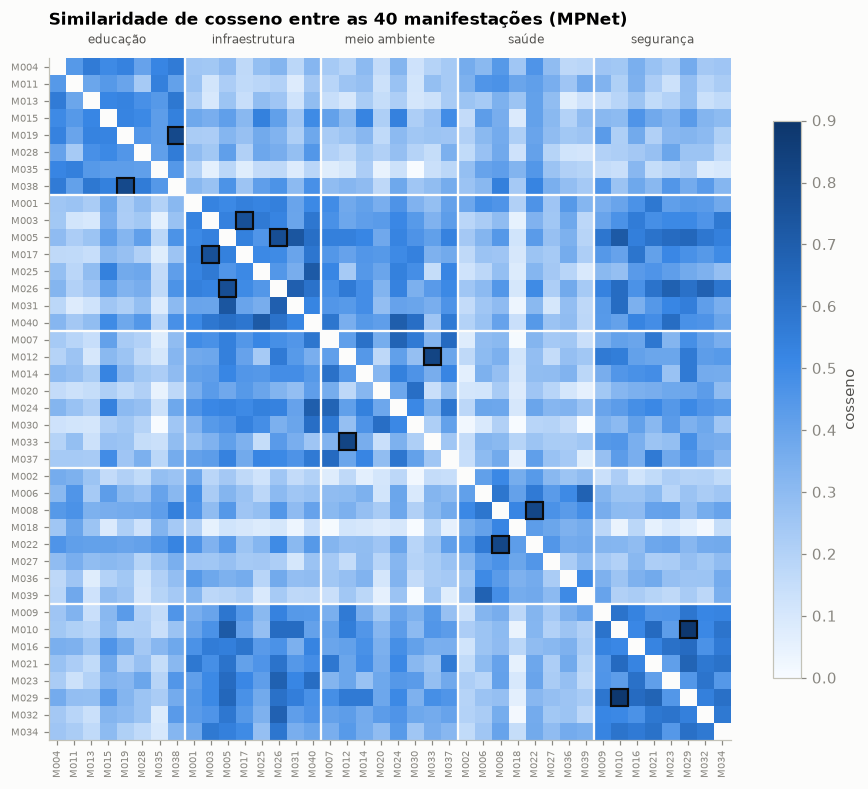

In [5]:
ordem = df.sort_values(["categoria_oficial", "id"]).index.to_numpy()
ids_ordenados = [ids[k] for k in ordem]
lugar = {mid: k for k, mid in enumerate(ids_ordenados)}

def heatmap(ax, S, titulo, vmin=0, vmax=1, rotulos=True):
    M = S[np.ix_(ordem, ordem)].copy()
    np.fill_diagonal(M, np.nan)                    # a diagonal (=1) só atrapalha a escala
    im = ax.imshow(M, cmap=oc.cmap_sequencial(), vmin=vmin, vmax=vmax)
    ax.grid(False)
    # separadores e nomes das categorias
    cats = df.loc[ordem, "categoria_oficial"].to_numpy()
    limites = [k for k in range(1, len(cats)) if cats[k] != cats[k - 1]]
    for b in limites:
        ax.axhline(b - 0.5, color="#fcfcfb", lw=1.5)
        ax.axvline(b - 0.5, color="#fcfcfb", lw=1.5)
    # duplicatas do gabarito
    for par in PARES_REAIS:
        a, b = sorted(par)
        for x, y in [(lugar[a], lugar[b]), (lugar[b], lugar[a])]:
            ax.add_patch(Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False, ec="#0b0b0b", lw=1.4))
    if rotulos:
        ax.set_xticks(range(len(ids)), ids_ordenados, rotation=90, fontsize=6.5)
        ax.set_yticks(range(len(ids)), ids_ordenados, fontsize=6.5)
        inicios = [0] + limites
        fins = limites + [len(cats)]
        for i0, i1 in zip(inicios, fins):
            ax.text((i0 + i1 - 1) / 2, -1.2, cats[i0], ha="center", va="bottom", fontsize=8, color="#52514e")
    else:
        ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(titulo, pad=22 if rotulos else 6)
    return im

fig, ax = plt.subplots(figsize=(10, 9.4))
im = heatmap(ax, SIM["MPNet"], "Similaridade de cosseno entre as 40 manifestações (MPNet)", vmin=0, vmax=0.9)
fig.colorbar(im, ax=ax, shrink=0.7, label="cosseno")
fig.savefig(FIGURAS / "e2_heatmap_mpnet.png")
plt.show()

**Leitura:** os blocos na diagonal mostram que manifestações da mesma categoria tendem a ser mais similares entre si,
principalmente **educação** e **saúde**, que têm vocabulário próprio. **Infraestrutura, segurança e meio ambiente**
se misturam mais (iluminação apagada é um problema de infraestrutura que o cidadão descreve como insegurança). As seis
duplicatas estão entre as células mais escuras, mas algumas células fora do gabarito também são escuras. Elas são os
candidatos a falso positivo.

A mesma matriz nos três modelos, **na mesma escala de cores (0 a 1)**:

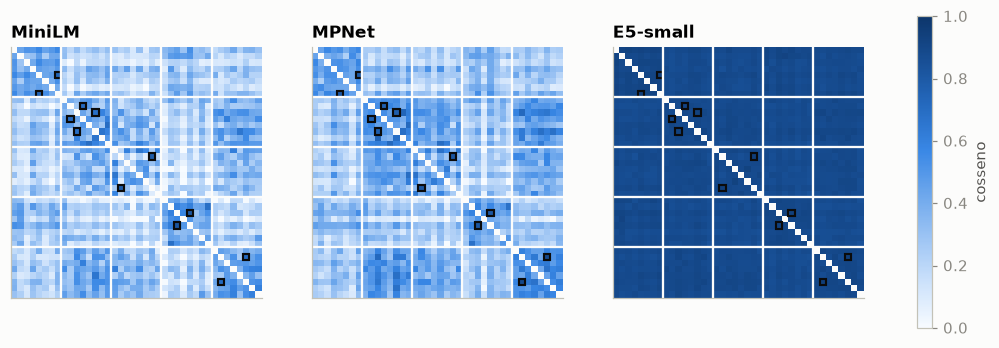

In [6]:
fig, eixos = plt.subplots(1, 3, figsize=(12.5, 4.6))
for ax, curto in zip(eixos, SIM):
    im = heatmap(ax, SIM[curto], curto, rotulos=False)
fig.colorbar(im, ax=eixos, shrink=0.8, label="cosseno")
fig.savefig(FIGURAS / "e2_heatmaps_modelos.png")
plt.show()

No E5 a matriz inteira é escura: todos os pares ficam entre ~0,83 e ~0,95. É a anisotropia já vista na Entrega 1. Um
limiar absoluto como 0,85 marcaria praticamente **todos** os pares como duplicatas nesse modelo.

## 3. Escolha e justificativa do limiar

Avaliamos quatro estratégias para cada modelo:

| Estratégia | Ideia |
|---|---|
| **Fixo 0,85** | Valor padrão do enunciado. |
| **Percentil 90** | Limiar dinâmico sugerido nas dicas: marca os 10% de pares mais similares. |
| **Percentil pela taxa esperada** | Se ~15% das manifestações são duplicatas, esperamos ≈ 0,15 × 40 = 6 pares entre 780 (0,77%) → percentil ≈ 99,2. |
| **Ótimo no gabarito** | Limiar que maximiza o F1 contra as 6 duplicatas reais. É otimista, porque é ajustado nos mesmos dados. |

In [7]:
def avaliar(curto, limiar):
    S = SIM[curto]
    detectados = {p for p, s in zip(PARES_TODOS, S[iu, ju]) if s >= limiar}
    return oc.avaliar_deteccao(detectados, PARES_REAIS) | {"pares marcados": len(detectados)}

grade = np.round(np.arange(0.40, 0.99, 0.005), 3)
varredura = pd.DataFrame(
    [{"modelo": c, "limiar": l, **avaliar(c, l)} for c in SIM for l in grade]
)

taxa_esperada = 0.15 * len(ids) / len(PARES_TODOS)    # 15% de 40 = 6 duplicatas -> ≈ 6 pares em 780
PERCENTIL_TAXA = 100 * (1 - taxa_esperada)

linhas = []
for curto in SIM:
    valores = SIM[curto][iu, ju]
    melhor = varredura[varredura.modelo == curto].sort_values(["F1", "limiar"], ascending=[False, True]).iloc[0]
    estrategias = {
        "fixo 0,85": 0.85,
        "percentil 90": np.percentile(valores, 90),
        f"percentil {PERCENTIL_TAXA:.1f} (taxa esperada)": np.percentile(valores, PERCENTIL_TAXA),
        "ótimo no gabarito": melhor["limiar"],
    }
    for nome_estrategia, limiar in estrategias.items():
        linhas.append({"modelo": curto, "estratégia": nome_estrategia, "limiar": limiar, **avaliar(curto, limiar)})

estrategias_df = pd.DataFrame(linhas).set_index(["modelo", "estratégia"])
estrategias_df.style.format({"limiar": "{:.3f}", "precisão": "{:.2f}", "revocação": "{:.2f}", "F1": "{:.2f}"})

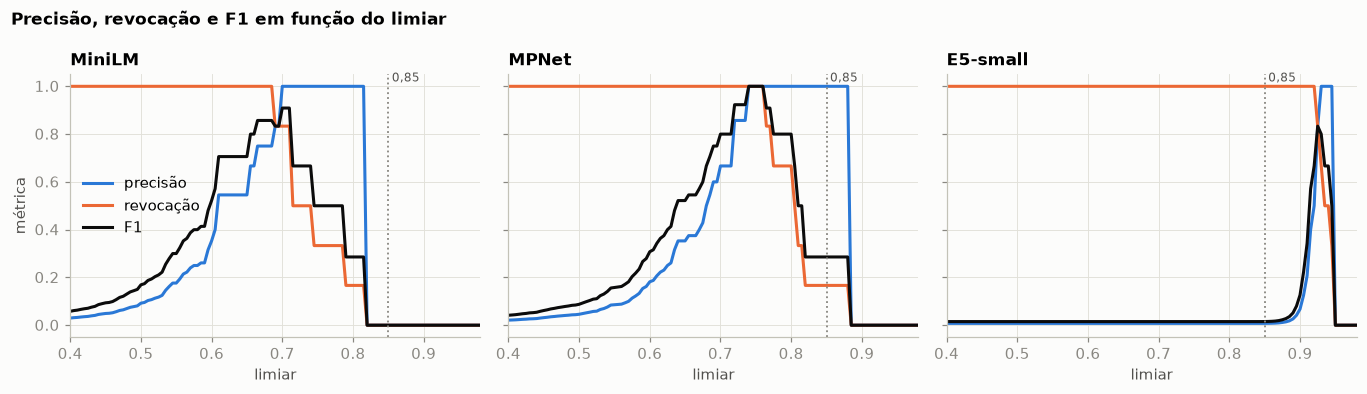

In [8]:
fig, eixos = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
for ax, curto in zip(eixos, SIM):
    v = varredura[varredura.modelo == curto]
    ax.plot(v.limiar, v["precisão"], color=oc.PALETA[0], lw=2, label="precisão")
    ax.plot(v.limiar, v["revocação"], color=oc.PALETA[1], lw=2, label="revocação")
    ax.plot(v.limiar, v["F1"], color="#0b0b0b", lw=2, label="F1")
    ax.axvline(0.85, color="#898781", ls=":", lw=1.2)
    ax.text(0.855, 1.02, "0,85", color="#52514e", fontsize=8)
    ax.set_title(curto)
    ax.set_xlabel("limiar")
    ax.set_xlim(0.4, 0.98)
eixos[0].set_ylabel("métrica")
eixos[0].legend(loc="center left")
fig.suptitle("Precisão, revocação e F1 em função do limiar", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURAS / "e2_varredura_limiar.png")
plt.show()

Para entender **por que** cada modelo tem uma faixa boa diferente, colocamos lado a lado a distribuição dos 774 pares
que não são duplicatas e as 6 duplicatas reais:

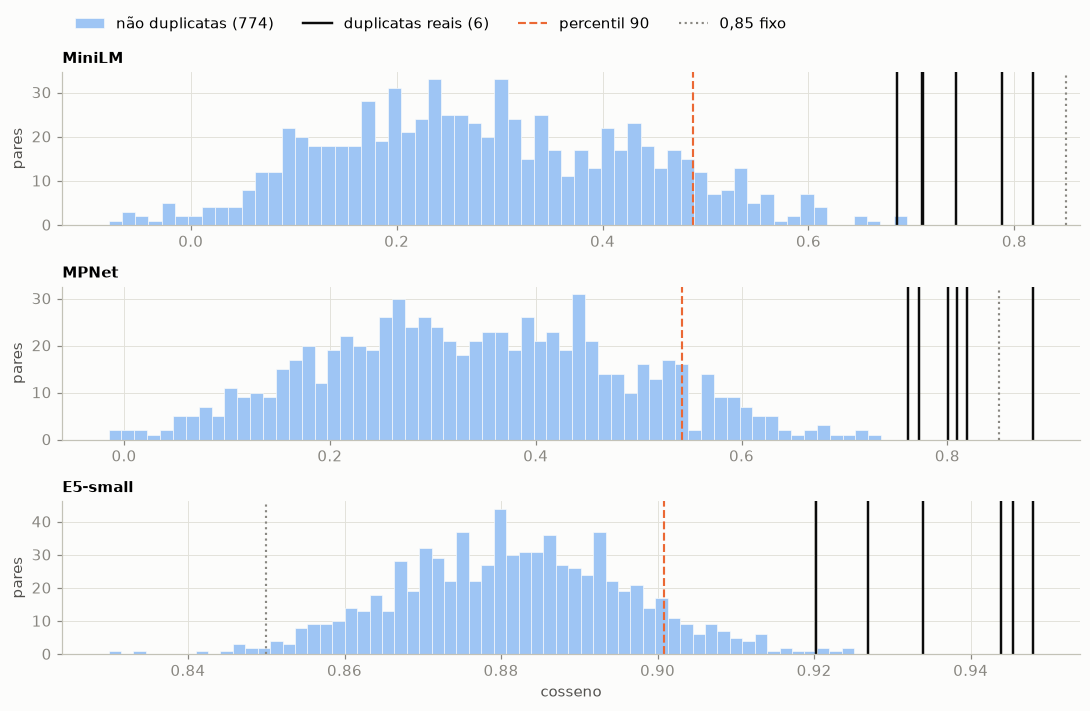

In [9]:
fig, eixos = plt.subplots(3, 1, figsize=(10, 6.6))
for ax, curto in zip(eixos, SIM):
    valores = SIM[curto][iu, ju]
    ax.hist(valores[~eh_dup], bins=60, color="#9ec5f4", edgecolor="#fcfcfb", linewidth=0.4, label="não duplicatas (774)")
    for s in valores[eh_dup]:
        ax.axvline(s, color="#0b0b0b", lw=1.6)
    ax.plot([], [], color="#0b0b0b", lw=1.6, label="duplicatas reais (6)")
    ax.axvline(np.percentile(valores, 90), color=oc.PALETA[1], ls="--", lw=1.4, label="percentil 90")
    ax.axvline(0.85, color="#898781", ls=":", lw=1.4, label="0,85 fixo")
    ax.set_title(curto, fontsize=10)
    ax.set_ylabel("pares")
eixos[0].legend(loc="upper left", ncol=4, bbox_to_anchor=(0, 1.45))
eixos[-1].set_xlabel("cosseno")
fig.tight_layout()
fig.savefig(FIGURAS / "e2_separacao.png")
plt.show()

In [10]:
# "Margem" de cada modelo: a duplicata mais fraca contra o não-duplicado mais forte
margem = []
for curto in SIM:
    valores = SIM[curto][iu, ju]
    k_nd = np.argmax(np.where(eh_dup, -np.inf, valores))
    k_d = np.argmin(np.where(eh_dup, valores, np.inf))
    margem.append({
        "modelo": curto,
        "duplicata mais fraca": f"{'×'.join(sorted(PARES_TODOS[k_d]))} ({valores[k_d]:.3f})",
        "não-duplicata mais forte": f"{'×'.join(sorted(PARES_TODOS[k_nd]))} ({valores[k_nd]:.3f})",
        "margem": valores[k_d] - valores[k_nd],
        "desvio-padrão dos pares": valores.std(),
        "margem em desvios-padrão": (valores[k_d] - valores[k_nd]) / valores.std(),
    })
pd.DataFrame(margem).set_index("modelo").style.format(precision=3)

,duplicata mais fraca,não-duplicata mais forte,margem,desvio-padrão dos pares,margem em desvios-padrão
modelo,,,,,
MiniLM,M005×M026 (0.686),M025×M040 (0.696),-0.010,0.152,-0.065
MPNet,M003×M017 (0.762),M005×M031 (0.736),0.026,0.151,0.171
E5-small,M003×M017 (0.920),M020×M030 (0.925),-0.005,0.015,-0.314


### Decisão: **MPNet com limiar 0,75**

* **Por que não 0,85?** No MiniLM e no MPNet as duplicatas reais ficam entre 0,69 e 0,88. O valor 0,85 só captura a
  mais escrita-parecida (revocação de 0 a 17%). No E5 acontece o contrário: 0,85 está *abaixo* do grosso da
  distribuição e marca centenas de pares.
* **Por que não o percentil 90?** Porque o número de pares cresce com o **quadrado** do número de manifestações. Aqui
  apenas 0,77% dos pares são duplicatas, e o p90 marca 78 pares para revisão, com precisão abaixo de 10%. Com 4.000
  manifestações/mês seriam ~800 mil pares marcados. A ideia de um limiar dinâmico é boa, mas o percentil precisa vir da
  **taxa esperada de duplicatas entre pares**, e não de um valor redondo. O "percentil pela taxa esperada" (≈ 99,2)
  dá F1 ≥ 0,83 nos três modelos, inclusive no E5, sem depender da escala do cosseno. É a melhor opção quando não
  há gabarito para calibrar.
* **Por que MPNet?** É o único modelo com **margem positiva**. Existe um intervalo (0,737–0,762) em que todas as
  duplicatas ficam acima e todos os outros pares abaixo. **0,75** fica no meio desse intervalo. No MiniLM não existe
  margem: a duplicata mais fraca (M005 × M026, 0,686) fica abaixo de M025 × M040 (0,696), que não é duplicata. No
  E5 a margem também é negativa (M003 × M017 = 0,920 contra M020 × M030 = 0,925).
* **Cuidado:** o limiar foi ajustado com apenas 6 exemplos positivos, e a margem do MPNet é pequena (≈ 0,03). Em
  produção, o valor deve ser revalidado com uma amostra rotulada maior. A seção 5 propõe uma faixa de revisão humana
  exatamente por isso.

## 4. Pares duplicados encontrados (MPNet, limiar 0,75)

In [11]:
MODELO_ESCOLHIDO, LIMIAR_ESCOLHIDO = "MPNet", 0.75

duplicatas = oc.detectar_duplicatas(
    textos, limiar=LIMIAR_ESCOLHIDO, ids=ids,
    nome_modelo=NOME_COMPLETO[MODELO_ESCOLHIDO], embeddings=EMB[MODELO_ESCOLHIDO],
)
duplicatas["no gabarito?"] = [
    "sim" if frozenset((a, b)) in PARES_REAIS else "NÃO" for a, b in zip(duplicatas.id_a, duplicatas.id_b)
]
duplicatas.style.format({"similaridade": "{:.3f}"}).hide(axis="index")

id_a,id_b,similaridade,texto_a,texto_b,no gabarito?
M010,M029,0.884,Um grupo de pessoas usa e vende drogas na Praça Tiradentes todas as noites. Os moradores estão com medo e ninguém mais passa por ali depois que escurece.,Toda noite tem gente consumindo e traficando entorpecentes na praça Tiradentes. A vizinhança está apavorada e não deixa mais as crianças brincarem lá.,sim
M012,M033,0.819,O bar da Rua Sete de Setembro coloca som altíssimo até as três da manhã em todo fim de semana. Ninguém da vizinhança consegue dormir.,"Todo sábado e domingo o bar da Sete de Setembro liga caixas de som no volume máximo e vai até de madrugada. É perturbação do sossego, idosos e bebês não conseguem descansar.",sim
M008,M022,0.810,O posto de saúde do bairro São José está sem médico há mais de um mês. Chego às seis da manhã para pegar ficha e sou mandado embora sem consulta.,Falta atendimento no PSF da Vila São José. Não tem doutor faz semanas e a gente volta pra casa sem ser atendido.,sim
M019,M038,0.800,O ônibus escolar que leva as crianças da zona rural não passou a semana inteira. Meus filhos estão perdendo aula e ninguém da secretaria dá explicação.,Faz cinco dias que o transporte escolar não aparece no Sítio Boa Vista e as crianças ficam sem ir para a escola. A secretaria não atende o telefone.,sim
M005,M026,0.772,"Poste apagado na Rua das Acácias, perto do número 85, faz quinze dias. A rua fica completamente escura e os moradores têm medo de sair à noite.",A iluminação pública da Rua das Acácias não funciona há duas semanas. À noite fica um breu total e já teve gente assaltada na frente de casa.,sim
M003,M017,0.762,"Tem um buraco enorme na Av. Brasil, em frente à padaria do número 1200. Só essa semana já vi dois motoqueiros caindo por causa dele. Alguém vai morrer ali.","Asfalto todo esburacado da avenida principal, pertinho da panificadora. As motos precisam desviar das crateras e uma hora vai acontecer um acidente grave.",sim


Os seis pares encontrados são exatamente as seis duplicatas do gabarito. Nenhum falso positivo, nenhum falso negativo.

## 5. Análise de falsos positivos e falsos negativos

Um limiar que acerta tudo neste conjunto pequeno diz pouco sobre os erros que o sistema vai cometer. Por isso analisamos
os erros **em limiares vizinhos e nos outros modelos**, que mostram onde está a fronteira difícil.

In [12]:
def classificar(curto, limiar):
    S = SIM[curto]
    linhas = []
    for par, s in zip(PARES_TODOS, S[iu, ju]):
        real, marcado = par in PARES_REAIS, s >= limiar
        if real or marcado:
            a, b = sorted(par)
            tipo = ("VP" if real and marcado else "FN" if real else
                    "FP (falso amigo do gabarito)" if par in FALSOS_AMIGOS else "FP")
            linhas.append({"modelo": curto, "limiar": limiar, "par": f"{a} × {b}", "cosseno": s, "resultado": tipo,
                           "texto A": textos[posicao[a]], "texto B": textos[posicao[b]]})
    return pd.DataFrame(linhas).sort_values("cosseno", ascending=False)

CENARIOS = [("MPNet", 0.85), ("MPNet", 0.75), ("MPNet", 0.70), ("MiniLM", 0.70), ("MiniLM", 0.65)]
resumo = pd.DataFrame([{"modelo": c, "limiar": l, **avaliar(c, l)} for c, l in CENARIOS]).set_index(["modelo", "limiar"])
resumo.style.format({"precisão": "{:.2f}", "revocação": "{:.2f}", "F1": "{:.2f}"}).format_index("{:.2f}", level=1)

### 5.1 Falsos positivos (pares marcados que não são duplicatas)

In [13]:
erros = pd.concat([classificar(c, l) for c, l in CENARIOS])
fps = erros[erros.resultado.str.startswith("FP")].drop_duplicates(["modelo", "par"])
fps.style.format({"cosseno": "{:.3f}", "limiar": "{:.2f}"}).hide(axis="index")

modelo,limiar,par,cosseno,resultado,texto A,texto B
MPNet,0.70,M005 × M031,0.736,FP (falso amigo do gabarito),"Poste apagado na Rua das Acácias, perto do número 85, faz quinze dias. A rua fica completamente escura e os moradores têm medo de sair à noite.",Lâmpada queimada na praça da Matriz. À noite não se enxerga nada e os idosos que caminhavam ali deixaram de ir.
MPNet,0.70,M005 × M010,0.717,FP,"Poste apagado na Rua das Acácias, perto do número 85, faz quinze dias. A rua fica completamente escura e os moradores têm medo de sair à noite.",Um grupo de pessoas usa e vende drogas na Praça Tiradentes todas as noites. Os moradores estão com medo e ninguém mais passa por ali depois que escurece.
MPNet,0.70,M025 × M040,0.716,FP,"Tem um buraco na Rua das Flores, no Jardim Primavera, perto da escola estadual. A prefeitura tapou com terra no mês passado, mas com a chuva o buraco voltou ainda maior.","A obra de drenagem que a prefeitura começou na Rua Marechal Deodoro em fevereiro está abandonada. Abriram uma vala enorme no meio da pista, cercaram com fitas que já foram arrancadas e desde abril não aparece nenhum operário. A rua está interditada há meses, os ônibus foram desviados e os moradores idosos precisam andar três quarteirões até o ponto. O asfalto ao redor da vala cedeu e formou vários buracos, e à noite não há nenhuma sinalização luminosa, então carros já caíram na valeta. A terra acumulada vira lama quando chove e entope os bueiros das ruas vizinhas. Os comerciantes da rua dizem que o movimento caiu pela metade. Queremos saber quando a obra será retomada e concluída."
MiniLM,0.65,M025 × M040,0.696,FP,"Tem um buraco na Rua das Flores, no Jardim Primavera, perto da escola estadual. A prefeitura tapou com terra no mês passado, mas com a chuva o buraco voltou ainda maior.","A obra de drenagem que a prefeitura começou na Rua Marechal Deodoro em fevereiro está abandonada. Abriram uma vala enorme no meio da pista, cercaram com fitas que já foram arrancadas e desde abril não aparece nenhum operário. A rua está interditada há meses, os ônibus foram desviados e os moradores idosos precisam andar três quarteirões até o ponto. O asfalto ao redor da vala cedeu e formou vários buracos, e à noite não há nenhuma sinalização luminosa, então carros já caíram na valeta. A terra acumulada vira lama quando chove e entope os bueiros das ruas vizinhas. Os comerciantes da rua dizem que o movimento caiu pela metade. Queremos saber quando a obra será retomada e concluída."
MiniLM,0.65,M006 × M039,0.686,FP,"Quero registrar uma reclamação grave sobre a UPA do Centro. No sábado levei minha mãe, de 78 anos, com febre alta e falta de ar, e esperamos mais de sete horas pelo atendimento. Na recepção disseram que havia apenas um clínico geral de plantão para toda a demanda. Ela ficou sentada numa cadeira de plástico no corredor, porque não havia maca disponível, e o soro foi pendurado num gancho improvisado na parede. Os banheiros estavam imundos, sem papel e sem sabonete. Quando finalmente foi atendida, o médico pediu um raio-x, mas o aparelho estava quebrado e tivemos que ir a um laboratório particular. Na volta, já de madrugada, o estacionamento estava sem iluminação e sem nenhum vigia. Exijo providências.",Fui tratada com grosseria pela recepcionista do Hospital Municipal. Ela gritou comigo na frente de todos quando perguntei quanto tempo ainda faltava para meu atendimento.
MiniLM,0.65,M026 × M031,0.663,FP (falso amigo do gabarito),A iluminação pública da Rua das Acácias não funciona há duas semanas. À noite fica um breu total e já teve gente assaltada na frente de casa.,Lâmpada queimada na praça da Matriz. À noite não se enxerga nada e os idosos que caminhavam ali deixaram de ir.
MiniLM,0.65,M007 × M024,0.654,FP,"O terreno baldio da Rua Ipê Amarelo virou depósito de lixo e entulho. Tem sofá velho, restos de construção e sacos de lixo. O cheiro é insuportável e já apareceram ratos e escorpiões nas casas vizinhas.","Venho denunciar a situação do córrego Ág

**Padrões dos falsos positivos**

1. **Mesmo tipo de problema, lugar diferente**, o caso mais frequente. M005 × M031 e M026 × M031 (iluminação apagada
   na Rua das Acácias × lâmpada queimada na praça da Matriz), dois "falsos amigos" do gabarito, descrevem o mesmo *tipo* de ocorrência.
   Para o modelo, que mede **semelhança de assunto**, eles são quase paráfrases. O que os diferencia é o endereço, e
   endereços são nomes próprios com pouco peso semântico no embedding.
2. **Temas vizinhos com consequências parecidas**. M005 × M010 (rua escura, "moradores têm medo de sair à noite" ×
   drogas na praça, "moradores estão com medo") compartilham o *medo noturno*, embora a causa seja outra. M023 × M026 (semáforo desligado × iluminação que não
   funciona) compartilham "equipamento público apagado".
3. **Textos longos com subtemas**. M025 × M040 (buraco que volta com a chuva × obra abandonada com "vários buracos") e,
   no MiniLM, M006 × M039 (UPA lotada × grosseria na recepção do hospital). Manifestações longas misturam assuntos e o
   embedding vira uma "média" deles, o que as aproxima de várias curtas ao mesmo tempo.

### 5.2 Falsos negativos (duplicatas reais que ficaram abaixo do limiar)

In [14]:
fns = erros[erros.resultado == "FN"].drop_duplicates(["modelo", "limiar", "par"])
fns.style.format({"cosseno": "{:.3f}", "limiar": "{:.2f}"}).hide(axis="index")

modelo,limiar,par,cosseno,resultado,texto A,texto B
MPNet,0.85,M012 × M033,0.819,FN,O bar da Rua Sete de Setembro coloca som altíssimo até as três da manhã em todo fim de semana. Ninguém da vizinhança consegue dormir.,"Todo sábado e domingo o bar da Sete de Setembro liga caixas de som no volume máximo e vai até de madrugada. É perturbação do sossego, idosos e bebês não conseguem descansar."
MPNet,0.85,M008 × M022,0.810,FN,O posto de saúde do bairro São José está sem médico há mais de um mês. Chego às seis da manhã para pegar ficha e sou mandado embora sem consulta.,Falta atendimento no PSF da Vila São José. Não tem doutor faz semanas e a gente volta pra casa sem ser atendido.
MPNet,0.85,M019 × M038,0.800,FN,O ônibus escolar que leva as crianças da zona rural não passou a semana inteira. Meus filhos estão perdendo aula e ninguém da secretaria dá explicação.,Faz cinco dias que o transporte escolar não aparece no Sítio Boa Vista e as crianças ficam sem ir para a escola. A secretaria não atende o telefone.
MPNet,0.85,M005 × M026,0.772,FN,"Poste apagado na Rua das Acácias, perto do número 85, faz quinze dias. A rua fica completamente escura e os moradores têm medo de sair à noite.",A iluminação pública da Rua das Acácias não funciona há duas semanas. À noite fica um breu total e já teve gente assaltada na frente de casa.
MPNet,0.85,M003 × M017,0.762,FN,"Tem um buraco enorme na Av. Brasil, em frente à padaria do número 1200. Só essa semana já vi dois motoqueiros caindo por causa dele. Alguém vai morrer ali.","Asfalto todo esburacado da avenida principal, pertinho da panificadora. As motos precisam desviar das crateras e uma hora vai acontecer um acidente grave."
MiniLM,0.70,M005 × M026,0.686,FN,"Poste apagado na Rua das Acácias, perto do número 85, faz quinze dias. A rua fica completamente escura e os moradores têm medo de sair à noite.",A iluminação pública da Rua das Acácias não funciona há duas semanas. À noite fica um breu total e já teve gente assaltada na frente de casa.


**Padrões dos falsos negativos**

* Com o limiar do enunciado (0,85), o MPNet perde 5 das 6 duplicatas. O único par acima dele é M010 × M029 (drogas na
  Praça Tiradentes), que repete o nome do local e tem estrutura quase idêntica.
* As duplicatas mais difíceis são **M005 × M026** (a mais fraca no MiniLM) e **M003 × M017** (a mais fraca no MPNet e no E5).
  Em M005 × M026 (poste apagado × iluminação pública não funciona), além do vocabulário diferente, M026 acrescenta um **segundo fato** ("já teve gente assaltada") que puxa o texto para
  segurança. Quando um cidadão acrescenta detalhes novos ao mesmo problema, a similaridade cai.
* **M003 × M017**, o par do enunciado, também fica perto da fronteira (0,71 no MiniLM, 0,76 no MPNet). M017 não cita
  o nome da avenida. Para o modelo, "avenida principal perto da panificadora" é compatível com a Av. Brasil, mas também
  com qualquer outra avenida.

### 5.3 O que isso significa para a ouvidoria: triagem em duas faixas

Os erros mostram que **similaridade semântica alta é condição necessária, mas não suficiente**, para duplicata: ela
identifica o *mesmo tipo de problema*, e confirmar *o mesmo caso* exige olhar o local. A proposta operacional é:

| Faixa (MPNet) | Ação |
|---|---|
| cosseno ≥ 0,75 | **Duplicata provável**: sugerir vínculo automático ao protocolo existente. |
| 0,65 ≤ cosseno < 0,75 | **Revisão humana**: mesmo tema; o atendente confere endereço e data. |
| < 0,65 | Tratar como manifestação nova. |

In [15]:
S = SIM[MODELO_ESCOLHIDO]
triagem = pd.DataFrame([
    {"par": "×".join(sorted(p)), "cosseno": s,
     "faixa": "duplicata provável" if s >= 0.75 else "revisão humana",
     "gabarito": "duplicata" if p in PARES_REAIS else ("falso amigo" if p in FALSOS_AMIGOS else "—")}
    for p, s in zip(PARES_TODOS, S[iu, ju]) if s >= 0.65
]).sort_values("cosseno", ascending=False)
print(f"{len(triagem)} pares acima de 0,65: "
      f"{(triagem.faixa == 'duplicata provável').sum()} automáticos + {(triagem.faixa == 'revisão humana').sum()} para revisão")
triagem.style.format({"cosseno": "{:.3f}"}).hide(axis="index")

17 pares acima de 0,65: 6 automáticos + 11 para revisão


par,cosseno,faixa,gabarito
M010×M029,0.884,duplicata provável,duplicata
M012×M033,0.819,duplicata provável,duplicata
M008×M022,0.810,duplicata provável,duplicata
M019×M038,0.800,duplicata provável,duplicata
M005×M026,0.772,duplicata provável,duplicata
M003×M017,0.762,duplicata provável,duplicata
M005×M031,0.736,revisão humana,falso amigo
M005×M010,0.717,revisão humana,—
M025×M040,0.716,revisão humana,—
M024×M040,0.699,revisão humana,—


Com essa triagem, **todas** as duplicatas são recuperadas na faixa automática e a fila de revisão humana contém só os
pares de fronteira: 11 pares, 1,4% dos 780, e justamente os casos em que o julgamento do atendente agrega valor.

## 6. Conclusão

* A função `detectar_duplicatas` funciona como pedido, mas o **limiar padrão 0,85 não serve** para os modelos testados:
  no MiniLM/MPNet ele perde quase todas as duplicatas e no E5 marca quase todos os pares.
* O limiar precisa ser **calibrado por modelo**. Um limiar dinâmico só funciona se o percentil vier da **taxa esperada
  de duplicatas entre pares** (≈ 99,2 aqui), e não de um valor fixo como 90.
* Escolhemos **MPNet + 0,75**, o único modelo com margem de separação positiva nesta base. Ele recuperou as 6 duplicatas
  sem falsos positivos. A margem é pequena, então o valor deve ser revalidado com mais dados rotulados.
* Os erros têm uma causa estrutural: embeddings medem **semelhança de assunto**, e não identidade do caso. Falsos
  positivos são problemas do mesmo tipo em locais diferentes; falsos negativos são duplicatas em que o cidadão
  acrescentou fatos novos. A evolução natural é combinar o cosseno com um **sinal de localização** (extração de
  endereço/bairro por NER ou regex) e manter uma faixa de revisão humana.